# Entregable final · Parte 1: evidencia de las correcciones y mejoras
**TFM Tema 50:** Integración y consolidación territorial de datos abiertos gubernamentales del Ecuador para la toma de decisiones
**Grupo:** Wilson Paredes, Diana Tandalla, Alexander Luna, Bryan Sarmiento

Este notebook recalcula, sobre los datos del TFM, el **antes y el después** de cada cambio documentado en el informe. Las secciones A1–A3 se recalculan aquí; B y C leen los archivos de resultados que generaron los notebooks del capítulo 4 y del Trabajo 3 (no se transcribe ninguna cifra a mano). Todas las cifras quedan en `resultados_entregable_final.json`.

| Sección | Observación o mejora | Entregable de origen |
|---|---|---|
| A1 | ¿Por qué KNN y por qué k = 5? | MLP |
| A2 | Se usó todo el dato antes de dividir (fuga de información) | MLP |
| A3 | Evaluar la generalización a cantones nuevos | MLP |
| A4 | Las cifras del notebook y del informe deben coincidir | MLP |
| B | Normalización por población, indicador constante, ampliación de la matriz, filtro de evidencia | Revisión del TFM |
| C | Modelo pre-entrenado frente al MLP desde cero | Transfer learning |

In [1]:
import json, warnings, numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ShuffleSplit, GroupShuffleSplit
from sklearn.metrics import f1_score, average_precision_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
N_REP, CONTAM, SEMILLA = 20, 0.05, 42
RES = {}
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## Datos: matriz de la entrega del MLP (1.284 cantón-año × 4 indicadores)
Se reconstruye exactamente la matriz con la que se evaluó el MLP: indicadores con dato en al menos el 40 % de las filas y filas con al menos el 30 % de los indicadores, en escala log(1 + conteo), con los ceros tratados como faltantes.

In [2]:
wide = pd.read_csv("matriz_canton_anio_28ind.csv", dtype={"cod_canton": str}).set_index(["cod_canton", "anio"])
w = wide.loc[:, (wide > 0).mean() >= 0.40]; W = w[(w > 0).mean(axis=1) >= 0.30]
canton = W.index.get_level_values(0).values; prov = np.array([c[:2] for c in canton])
Xraw = np.log1p(W.values.astype(float)); Xraw[W.values == 0] = np.nan
print(f"matriz: {W.shape[0]} filas x {W.shape[1]} indicadores, {len(set(canton))} cantones; faltantes: {np.isnan(Xraw).mean():.1%}")

matriz: 1284 filas x 4 indicadores, 218 cantones; faltantes: 20.6%


## A1. Elección del imputador (observación: ¿por qué KNN y por qué k = 5?)
Se ocultan al azar el 10 % de los valores observados, se imputan y se mide el error (RMSE) contra el valor real; 10 repeticiones. Se compara KNN con k = 5 (antes), la media de la columna (referencia trivial) y la mediana de los demás años del mismo cantón (después).

In [3]:
class ImputadorHistoria:
    def fit(self, X): self.media_ = np.nanmean(X, axis=0); return self
    def transform(self, X, grupos):
        med = pd.DataFrame(X).groupby(np.asarray(grupos)).transform("median").values
        return np.where(np.isnan(X), np.where(np.isnan(med), self.media_, med), X)

obs = np.argwhere(~np.isnan(Xraw)); rng = np.random.RandomState(0)
err = {"KNN k=5 (antes)": [], "Media de la columna": [], "Historia del cantón (después)": []}
for _ in range(10):
    sel = obs[rng.choice(len(obs), int(0.1 * len(obs)), replace=False)]
    Xm = Xraw.copy(); real = Xraw[sel[:, 0], sel[:, 1]]; Xm[sel[:, 0], sel[:, 1]] = np.nan
    for k, Xi in (("KNN k=5 (antes)", KNNImputer(n_neighbors=5).fit_transform(Xm)),
                  ("Media de la columna", SimpleImputer().fit_transform(Xm)),
                  ("Historia del cantón (después)", ImputadorHistoria().fit(Xm).transform(Xm, canton))):
        err[k].append(np.sqrt(np.mean((Xi[sel[:, 0], sel[:, 1]] - real) ** 2)))
A1 = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in err.items()}, index=["RMSE", "desv."]).T.round(3)
RES["A1_imputador"] = A1.to_dict("index"); A1

,RMSE,desv.
KNN k=5 (antes),1.414,0.079
Media de la columna,1.335,0.063
Historia del cantón (después),0.737,0.024


## A2. Fuga de información (observación: se usó todo el dato antes de dividir)
**Antes:** el imputador KNN, el escalado y los tres detectores (de los que sale la etiqueta) se ajustaban con **todas** las filas, y después se dividía en entrenamiento y prueba. **Después:** todo se ajusta solo con entrenamiento y la etiqueta de prueba se obtiene aplicando los detectores ya ajustados a las filas de prueba. Mismo MLP (16-8, sobremuestreo) y mismas 20 divisiones al azar.

In [4]:
def detectores(Xtr, s):
    iso = IsolationForest(n_estimators=300, contamination=CONTAM, random_state=s).fit(Xtr)
    lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM); v = (iso.predict(Xtr) == -1).astype(int) + (lof.fit_predict(Xtr) == -1)
    lof_nv = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM, novelty=True).fit(Xtr)
    sc = StandardScaler().fit(Xtr); svm = OneClassSVM(kernel="rbf", nu=CONTAM, gamma="scale").fit(sc.transform(Xtr))
    v = v + (svm.predict(sc.transform(Xtr)) == -1)
    return v, lambda X: (iso.predict(X) == -1).astype(int) + (lof_nv.predict(X) == -1) + (svm.predict(sc.transform(X)) == -1)

def mlp(Ztr, ytr, Zte, s):
    rg = np.random.RandomState(s); pos = np.where(ytr == 1)[0]; extra = rg.choice(pos, (ytr == 0).sum() - len(pos))
    m = MLPClassifier(hidden_layer_sizes=(16, 8), learning_rate_init=1e-3, batch_size=64, max_iter=150, n_iter_no_change=150,
                      random_state=s).fit(np.vstack([Ztr, Ztr[extra]]), np.r_[ytr, ytr[extra]])
    return m.predict_proba(Zte)[:, 1]

def division(esq, s):
    i = np.arange(len(Xraw))
    if esq == "Filas al azar": return next(ShuffleSplit(1, test_size=0.2, random_state=s).split(i))
    return next(GroupShuffleSplit(1, test_size=0.2, random_state=s).split(i, groups=canton if esq == "Cantones nuevos" else prov))

def con_fuga(tr, te, s):
    X = KNNImputer(n_neighbors=5).fit_transform(Xraw)          # todo el dato
    v, _ = detectores(X, s); y = (v >= 2).astype(int)        # etiquetas con todo el dato
    Z = StandardScaler().fit_transform(X)
    return y[te], mlp(Z[tr], y[tr], Z[te], s), y[tr].sum()

def sin_fuga(tr, te, s):
    imp = ImputadorHistoria().fit(Xraw[tr]); Xtr, Xte = imp.transform(Xraw[tr], canton[tr]), imp.transform(Xraw[te], canton[te])
    v, f = detectores(Xtr, s); ytr, yte = (v >= 2).astype(int), (f(Xte) >= 2).astype(int)
    sc = StandardScaler().fit(Xtr)
    return yte, mlp(sc.transform(Xtr), ytr, sc.transform(Xte), s), ytr.sum()

def evaluar(fn, esq):
    out = []
    for s in range(N_REP):
        tr, te = division(esq, s); yte, p, npos = fn(tr, te, s)
        if npos < 3 or yte.sum() == 0: continue
        out.append(dict(f1=f1_score(yte, (p >= 0.5).astype(int), zero_division=0), pr_auc=average_precision_score(yte, p)))
    return pd.DataFrame(out).agg(["mean", "std"]).round(3)

A2 = pd.concat({"Con fuga (antes)": evaluar(con_fuga, "Filas al azar"), "Sin fuga (después)": evaluar(sin_fuga, "Filas al azar")})
RES["A2_fuga"] = {k: A2.loc[k].to_dict() for k in A2.index.get_level_values(0).unique()}; A2

f1  pr_auc
Con fuga (antes)   mean  0.696   0.847
                   std   0.083   0.073
Sin fuga (después) mean  0.649   0.784
                   std   0.138   0.152

## A3. Generalización territorial (observación: evaluar con cantones nuevos)
**Antes:** solo división de filas al azar, en la que el mismo cantón aparece en entrenamiento y en prueba con años distintos. **Después:** se agregan divisiones que reservan cantones completos y provincias completas.

In [5]:
A3 = pd.concat({e: evaluar(sin_fuga, e) for e in ("Filas al azar", "Cantones nuevos", "Provincias nuevas")})
RES["A3_generalizacion"] = {k: A3.loc[k].to_dict() for k in A3.index.get_level_values(0).unique()}; A3

f1  pr_auc
Filas al azar     mean  0.649   0.784
                  std   0.138   0.152
Cantones nuevos   mean  0.634   0.728
                  std   0.204   0.221
Provincias nuevas mean  0.543   0.628
                  std   0.211   0.226

## A4. Consistencia entre notebook e informe
Desde la entrega del MLP, cada notebook guarda sus cifras en un JSON y el informe se genera a partir de él: `resultados_cap3_v2.json`, `resultados_cap4.json`, `resultados_trabajo3.json` y este `resultados_entregable_final.json`. Abajo se verifica que las cifras de la entrega del MLP que cita el informe se reproducen.

In [6]:
v2 = json.load(open("resultados_cap3_v2.json"))
chk = pd.DataFrame({"JSON entrega MLP": [v2["imputacion"]["KNN k=5"]["rmse"], v2["imputacion"]["Historia del cantón (mediana otros años)"]["rmse"], v2["generalizacion"]["Cantones nuevos | MLP"]["f1"][0]],
                    "Recalculado aquí": [A1.loc["KNN k=5 (antes)", "RMSE"], A1.loc["Historia del cantón (después)", "RMSE"], A3.loc[("Cantones nuevos", "mean"), "f1"]]},
                   index=["RMSE KNN k=5", "RMSE historia del cantón", "F1 MLP cantones nuevos"])
chk["diferencia"] = (chk.iloc[:, 1] - chk.iloc[:, 0]).round(3); RES["A4_consistencia"] = chk.to_dict("index"); chk

,JSON entrega MLP,Recalculado aquí,diferencia
RMSE KNN k=5,1.414,1.414,0.000
RMSE historia del cantón,0.737,0.737,0.000
F1 MLP cantones nuevos,0.628,0.634,0.006


## B. Mejoras derivadas de la revisión del modelo (capítulo 4 del TFM)
Se leen de `resultados_cap4.json` (generado por `analisis_cap4.py`) y de `resultados_cap3_v2.json`.

In [7]:
c4 = json.load(open("resultados_cap4.json")); E, H, V3 = c4["modelos"]["elegida"], c4["modelos"]["elegida_historia"], c4["modelos"]["v3_tasas"]
iess = v2["iess_constante"]
B = pd.DataFrame([
    ["Normalización por población", "Casos de Quito, Guayaquil o Cuenca en el top-30", v2["auditoria"]["top30_en_3_ciudades"], V3["top30_quito_gye_cuenca"]],
    ["Matrices de presencia y de valores", "Correlación del puntaje con la cobertura de la fila", v2["correlaciones"]["Matriz original con ceros (28 ind., 1.768 filas) · Isolation Forest"], E["corr_S_cobertura"]],
    ["Indicador constante (IESS) excluido", "% de cantones con el mismo valor (mediana por año)", float(np.median([d["% de cantones en el valor modal"] for d in iess.values()])), "fuera del modelo"],
    ["Ventana de años en el filtro de cobertura", "Indicadores / instituciones en la matriz", "4 / 4", f"{E['matriz'][1]} / 8"],
    ["Filtro de evidencia observada", "Casos del top-30 explicados por un valor imputado", H["top30_dominante_imputado"], E["top30_dominante_imputado"]],
    ["Puntaje único S_ens", "Jaccard del top-30 en submuestras del 80 %", v2["estabilidad"]["Ensamble · 30 submuestras 80 %"]["medio"], E["jaccard_submuestras"][0]],
], columns=["Cambio", "Métrica", "Antes", "Después"])
RES["B_mejoras_tfm"] = B.to_dict("records"); B

,Cambio,Métrica,Antes,Después
0,Normalización por población,"Casos de Quito, Guayaquil o Cuenca en el top-30",15,1
1,Matrices de presencia y de valores,Correlación del puntaje con la cobertura de la...,0.817,0.1
2,Indicador constante (IESS) excluido,% de cantones con el mismo valor (mediana por ...,97.1,fuera del modelo
3,Ventana de años en el filtro de cobertura,Indicadores / instituciones en la matriz,4 / 4,10 / 8
4,Filtro de evidencia observada,Casos del top-30 explicados por un valor imputado,15,0
5,Puntaje único S_ens,Jaccard del top-30 en submuestras del 80 %,0.818,0.746


## C. Transfer learning: modelo pre-entrenado frente al MLP desde cero
Se leen de `resultados_trabajo3.json` (notebook `Trabajo3_TransferLearning_TFM_Tema50.ipynb`), matriz del capítulo 4 (807 × 10), 10 repeticiones por esquema.

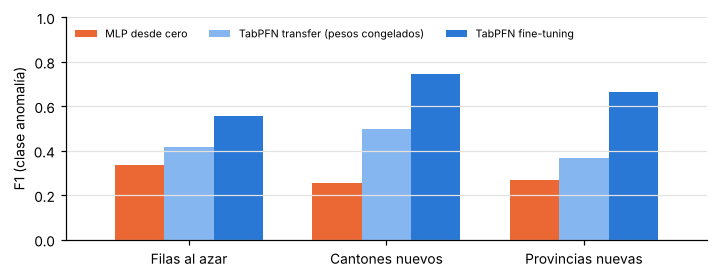

,MLP desde cero,TabPFN transfer (pesos congelados),TabPFN fine-tuning
Filas al azar,0.338,0.417,0.558
Cantones nuevos,0.253,0.498,0.747
Provincias nuevas,0.267,0.366,0.664


In [8]:
t3 = json.load(open("resultados_trabajo3.json"))["tabla"]
Cc = pd.DataFrame({m: {e: t3[f"{e} | {m}"]["f1"][0] for e in ("Filas al azar", "Cantones nuevos", "Provincias nuevas")}
                   for m in ("MLP desde cero", "TabPFN transfer (pesos congelados)", "TabPFN fine-tuning")}).round(3)
RES["C_transfer"] = Cc.to_dict()
fig, ax = plt.subplots(figsize=(6.6, 2.6)); Cc.plot.bar(ax=ax, color=["#eb6834", "#86b6ef", "#2a78d6"], width=0.75, rot=0)
ax.set_ylabel("F1 (clase anomalía)"); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper left"); ax.grid(axis="y", color="#e4e3df")
plt.tight_layout(); plt.savefig("fig_final_transfer.png", dpi=200); plt.show(); Cc

In [9]:
json.dump(RES, open("resultados_entregable_final.json", "w"), ensure_ascii=False, indent=1, default=float)
print(json.dumps({k: RES[k] for k in ("A1_imputador", "A2_fuga")}, ensure_ascii=False, indent=1, default=float))

{
 "A1_imputador": {
  "KNN k=5 (antes)": {
   "RMSE": 1.414,
   "desv.": 0.079
  },
  "Media de la columna": {
   "RMSE": 1.335,
   "desv.": 0.063
  },
  "Historia del cantón (después)": {
   "RMSE": 0.737,
   "desv.": 0.024
  }
 },
 "A2_fuga": {
  "Con fuga (antes)": {
   "f1": {
    "mean": 0.696,
    "std": 0.083
   },
   "pr_auc": {
    "mean": 0.847,
    "std": 0.073
   }
  },
  "Sin fuga (después)": {
   "f1": {
    "mean": 0.649,
    "std": 0.138
   },
   "pr_auc": {
    "mean": 0.784,
    "std": 0.152
   }
  }
 }
}
